In [13]:
!nvidia-smi
!pip list

Thu Oct 15 10:50:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   74C    P0             32W /   70W |    4455MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
%%writefile lab05_lib.py
# ЛР 5. Запуск открытой модели text-to-image. Библиотека учебных функций.
# Проверено 19.09.2026: Google Colab, GPU T4, Python 3.13, torch 2.11.0+cu128, diffusers 0.40.0, transformers 5.16.1.
# Модель: stabilityai/sd-turbo, ревизия закреплена (см. REVISION). Веса загружаются с Hugging Face без авторизации.
import hashlib, io, time
import numpy as np
import torch
from PIL import Image
from diffusers import AutoPipelineForText2Image
from diffusers.utils import logging as dlog

dlog.set_verbosity_error()  # убирает предупреждения о приведении типов при pipe.to(dtype)

MODEL_ID = "stabilityai/sd-turbo"
REVISION = "b261bac6fd2cf515557d5d0707481eafa0485ec2"

# Пять контекстов (брифов). Во всех запретены текст, логотипы и люди.
BRIEFS = [
    "editorial poster concept for a robotics festival, glowing mechanical arm silhouette, deep blue and amber palette, clean composition, no text, no logo, no people",
    "square podcast cover about the city environment, abstract layered skyline of geometric shapes, teal and orange palette, minimal flat style, no text, no people",
    "poster concept for a science exhibition, abstract constellation of connected nodes, dark background with white and cyan lines, balanced composition, no text, no logo",
    "visual for an ecology lecture series, stylized forest canopy seen from above, layered green shapes, soft morning light, no text, no people",
    "cover art for an electronic music release, brushed metal surface with iridescent reflections, macro photography style, strong contrast, no text, no logo, no people",
]


def load_pipe(dtype=torch.float16):
    """Загружает закреплённую ревизию (файлы fp16) на GPU; dtype задаёт тип вычислений."""
    pipe = AutoPipelineForText2Image.from_pretrained(
        MODEL_ID, revision=REVISION, torch_dtype=torch.float16, variant="fp16", use_safetensors=True)
    pipe.set_progress_bar_config(disable=True)
    return pipe.to("cuda", dtype)


def generate(pipe, prompt, seed, steps=1, guidance=0.0, size=512, batch=1, gen_device="cpu"):
    """Возвращает список PIL-изображений. Для каждого элемента пакета свой генератор: seed, seed+1, ..."""
    gens = [torch.Generator(device=gen_device).manual_seed(seed + i) for i in range(batch)]
    return pipe(prompt=[prompt] * batch, num_inference_steps=steps, guidance_scale=guidance,
                height=size, width=size, generator=gens).images


def generate_fixed_noise(pipe, prompt, seed, steps=1, guidance=0.0, size=512):
    """Начальный шум всегда строится в float32 и приводится к типу вычислений: так меняется только точность."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    lat = torch.randn((1, 4, size // 8, size // 8), generator=g, dtype=torch.float32).to("cuda", pipe.unet.dtype)
    return pipe(prompt=[prompt], num_inference_steps=steps, guidance_scale=guidance, height=size, width=size, latents=lat).images[0]


def png_bytes(img):
    buf = io.BytesIO()
    img.save(buf, format="PNG")
    return buf.getvalue()


def sha(data):
    return hashlib.sha256(data).hexdigest()


def to_arr(img):
    return np.asarray(img.convert("RGB"), dtype=np.float64)


def psnr_db(a, b):
    """PSNR для значений 0..255; inf, если изображения совпадают."""
    mse = np.mean((to_arr(a) - to_arr(b)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)


def max_abs_diff(a, b):
    return int(np.max(np.abs(to_arr(a) - to_arr(b))))


def jpeg_roundtrip(img, quality=90):
    buf = io.BytesIO()
    img.save(buf, format="JPEG", quality=quality)
    buf.seek(0)
    return Image.open(buf).convert("RGB"), buf.getvalue()


def classify(psnr, tol_db=40.0):
    """Классификация пары по допуску, заданному до эксперимента."""
    return "identical" if psnr == float("inf") else ("close" if psnr >= tol_db else "different")


# Шесть условий сравнения (фактор варианта). Каждое условие даёт пару изображений A и B.
CONDITIONS = ["repeat", "seed_plus_1", "generator_device", "dtype", "file_format", "batch"]


def make_pair(pipe, prompt, seed, cond):
    if cond == "repeat":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed)[0]
    elif cond == "seed_plus_1":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed + 1)[0]
    elif cond == "generator_device":
        a = generate(pipe, prompt, seed, gen_device="cpu")[0]; b = generate(pipe, prompt, seed, gen_device="cuda")[0]
    elif cond == "dtype":
        pipe.to(torch.float16); a = generate(pipe, prompt, seed)[0]
        pipe.to(torch.float32); b = generate(pipe, prompt, seed)[0]
        pipe.to(torch.float16)
    elif cond == "file_format":
        a = generate(pipe, prompt, seed)[0]; b, _ = jpeg_roundtrip(a, 90)
    elif cond == "batch":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed, batch=4)[0]
    else:
        raise ValueError(cond)
    return a, b


def variant_summary(pipe, n):
    """Вариант n = 1..30: контекст c = (n-1)//6 + 1, условие k = (n-1)%6 + 1."""
    c, k = (n - 1) // 6, (n - 1) % 6
    seed = 1000 + n
    t0 = time.perf_counter()
    a, b = make_pair(pipe, BRIEFS[c], seed, CONDITIONS[k])
    dt = time.perf_counter() - t0
    p = psnr_db(a, b)
    pf = None
    if CONDITIONS[k] == "dtype":  # проверка причины: одинаковый начальный шум в обоих режимах
        pipe.to(torch.float16); fa = generate_fixed_noise(pipe, BRIEFS[c], seed)
        pipe.to(torch.float32); fb = generate_fixed_noise(pipe, BRIEFS[c], seed)
        pipe.to(torch.float16); pf = psnr_db(fa, fb)
    return dict(variant=n, ctx=c + 1, cond=CONDITIONS[k], seed=seed, sha_a=sha(png_bytes(a)), sha_b=sha(png_bytes(b)),
                pixel_equal=bool(np.array_equal(to_arr(a), to_arr(b))), max_diff=max_abs_diff(a, b), psnr=p,
                verdict=classify(p), seconds=round(dt, 2), psnr_fixed_noise=pf)


Writing lab05_lib.py


In [5]:
%%writefile lab06_lib.py
# ЛР 6. Исследование параметров text-to-image генерации. Библиотека учебных функций.
# Требуется файл lab05_lib.py из ЛР 5 в той же папке (из него берутся модель, генерация и брифы).
# Проверено 19.09.2026: Google Colab, GPU T4, Python 3.13, torch 2.11.0+cu128, diffusers 0.40.0, transformers 5.16.1.
import time
import numpy as np
import torch
from scipy import ndimage
from transformers import CLIPModel, CLIPProcessor
import lab05_lib as L

CLIP_ID = "openai/clip-vit-base-patch32"
CLIP_REVISION = "3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268"
SEEDS = range(101, 106)

# Короткие запросы (только предмет) и русские переводы брифов из ЛР 5.
SHORT = ["robotic arm poster", "podcast cover about the city", "science exhibition poster",
         "ecology lecture visual, forest", "electronic music cover art"]
RU = [
    "плакат-концепт для фестиваля робототехники, светящийся силуэт механической руки, глубокий синий и янтарный цвета, чистая композиция, без текста, без логотипа, без людей",
    "квадратная обложка подкаста о городской среде, абстрактный многослойный горизонт из геометрических фигур, бирюзовый и оранжевый цвета, минималистичный плоский стиль, без текста, без людей",
    "плакат-концепт научной выставки, абстрактное созвездие соединённых узлов, тёмный фон с белыми и голубыми линиями, сбалансированная композиция, без текста, без логотипа",
    "визуал для цикла лекций по экологии, стилизованный полог леса сверху, многослойные зелёные формы, мягкий утренний свет, без текста, без людей",
    "обложка электронного музыкального релиза, шлифованная металлическая поверхность с радужными бликами, стиль макросъёмки, сильный контраст, без текста, без логотипа, без людей",
]

# Шесть факторов: (имя, изменение A -> B). Базовый режим: структурированный английский запрос, 512, 1 шаг, guidance 0.
FACTORS = ["steps_1_to_4", "size_512_to_384", "size_512_to_768", "prompt_short_to_structured", "guidance_0_to_3", "language_en_to_ru"]


def load_clip():
    model = CLIPModel.from_pretrained(CLIP_ID, revision=CLIP_REVISION).to("cuda").eval()
    proc = CLIPProcessor.from_pretrained(CLIP_ID, revision=CLIP_REVISION)
    return model, proc


@torch.no_grad()
def clip_sim(clip, img, text):
    """Косинусное сходство изображения и текста в CLIP, умноженное на 100 (не CLIPScore)."""
    model, proc = clip
    inp = proc(text=[text], images=img, return_tensors="pt", padding=True, truncation=True).to("cuda")
    out = model(**inp)
    a = out.image_embeds / out.image_embeds.norm(dim=-1, keepdim=True)
    b = out.text_embeds / out.text_embeds.norm(dim=-1, keepdim=True)
    return float((a * b).sum()) * 100


def luma(img):
    x = np.asarray(img.convert("RGB"), dtype=np.float64) / 255
    return 0.299 * x[..., 0] + 0.587 * x[..., 1] + 0.114 * x[..., 2]


def edge_energy(img):
    """Средняя длина градиента яркости (оператор Собеля, нормировка 1/8), как в ЛР 4."""
    y = luma(img)
    return float(np.mean(np.hypot(ndimage.sobel(y, axis=0), ndimage.sobel(y, axis=1)) / 8))


def contrast(img):
    return float(np.std(luma(img)))


def settings(factor, c):
    """Пара режимов (A, B) для контекста c = 0..4: словарь параметров generate() плюс текст запроса."""
    base = dict(prompt=L.BRIEFS[c], steps=1, guidance=0.0, size=512)
    a, b = dict(base), dict(base)
    if factor == "steps_1_to_4":
        b["steps"] = 4
    elif factor == "size_512_to_384":
        b["size"] = 384
    elif factor == "size_512_to_768":
        b["size"] = 768
    elif factor == "prompt_short_to_structured":
        a["prompt"] = SHORT[c]
    elif factor == "guidance_0_to_3":
        b["guidance"] = 3.0
    elif factor == "language_en_to_ru":
        b["prompt"] = RU[c]
    else:
        raise ValueError(factor)
    return a, b


def measure(pipe, clip, cfg, c, seed):
    """Одно изображение: метрики и время генерации, с; сходство CLIP считается с исходным английским брифом."""
    t0 = time.perf_counter()
    img = L.generate(pipe, cfg["prompt"], seed, steps=cfg["steps"], guidance=cfg["guidance"], size=cfg["size"])[0]
    dt = time.perf_counter() - t0
    return dict(clip=clip_sim(clip, img, L.BRIEFS[c]), edge=edge_energy(img), contrast=contrast(img), seconds=dt), img


def variant_summary(pipe, clip, n, seeds=SEEDS):
    """Вариант n = 1..30: контекст c = (n-1)//6, фактор k = (n-1)%6. Для каждой метрики: A, s, B, разность, |d|/s, признак |d| > 2s."""
    c, k = (n - 1) // 6, (n - 1) % 6
    a_cfg, b_cfg = settings(FACTORS[k], c)
    A = {m: [] for m in ("clip", "edge", "contrast", "seconds")}
    B = {m: [] for m in A}
    for cfg in (a_cfg, b_cfg):  # прогрев: первый вызов с новым размером и числом шагов медленнее
        L.generate(pipe, cfg["prompt"], 0, steps=cfg["steps"], guidance=cfg["guidance"], size=cfg["size"])
    for s in seeds:
        ma, _ = measure(pipe, clip, a_cfg, c, s)
        mb, _ = measure(pipe, clip, b_cfg, c, s)
        for m in A:
            A[m].append(ma[m]); B[m].append(mb[m])
    rows = []
    for m in A:
        d = np.mean(B[m]) - np.mean(A[m]); sa = np.std(A[m], ddof=1)
        rows.append((m, float(np.mean(A[m])), float(sa), float(np.mean(B[m])), float(d), float(abs(d) / sa) if sa > 0 else float("inf"), bool(abs(d) > 2 * sa)))
    return dict(variant=n, ctx=c + 1, factor=FACTORS[k], rows=rows)

Writing lab06_lib.py


In [7]:
!sha256sum lab05_lib.py lab06_lib.py

4eb176506585ffcda1702605a767309fb451808229c3622f80ce882b7fa2ce1a  lab05_lib.py
c6d8473cf5a3000f4c27fbdef57916c2fbce347db272928d5c4729472f748bd8  lab06_lib.py


In [8]:
import lab05_lib as L
import lab06_lib as M

pipe = L.load_pipe()
clip = M.load_clip()

[transformers] `Siglip2ImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `Siglip2ImageProcessor` instead.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

In [9]:
a, b = M.settings("size_512_to_384", 4)   # c=4 — бриф 5
print("A:", a)
print("B:", b)

A: {'prompt': 'cover art for an electronic music release, brushed metal surface with iridescent reflections, macro photography style, strong contrast, no text, no logo, no people', 'steps': 1, 'guidance': 0.0, 'size': 512}
B: {'prompt': 'cover art for an electronic music release, brushed metal surface with iridescent reflections, macro photography style, strong contrast, no text, no logo, no people', 'steps': 1, 'guidance': 0.0, 'size': 384}


In [10]:
res = M.variant_summary(pipe, clip, 26)
print("Вариант", res["variant"], "фактор", res["factor"])
for m, a, s, b, d, ratio, sig in res["rows"]:
    print(f"{m:9s} A={a:.4f} s={s:.4f} B={b:.4f} d={d:+.4f} |d|/s={ratio:.2f} 2s={'да' if sig else 'нет'}")

Вариант 26 фактор size_512_to_384
clip      A=27.6343 s=1.0640 B=29.7356 d=+2.1013 |d|/s=1.97 2s=нет
edge      A=0.0353 s=0.0123 B=0.0313 d=-0.0041 |d|/s=0.33 2s=нет
contrast  A=0.1345 s=0.0199 B=0.1391 d=+0.0046 |d|/s=0.23 2s=нет
seconds   A=0.2843 s=0.0022 B=0.1885 d=-0.0958 |d|/s=43.22 2s=да


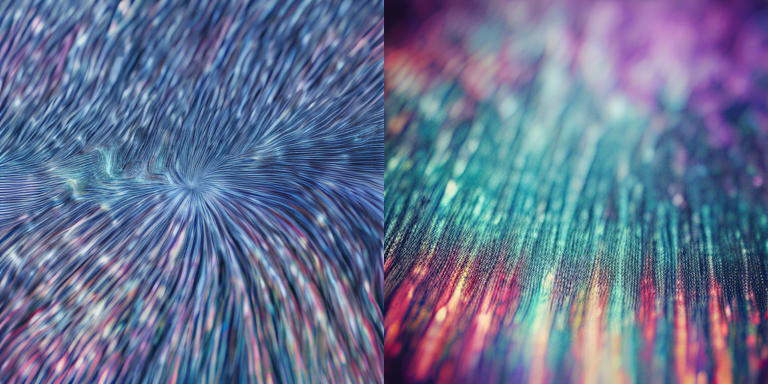

In [11]:
from PIL import Image
a_cfg, b_cfg = M.settings("size_512_to_384", 4)
pair = [
    L.generate(pipe, a_cfg["prompt"], 101, steps=a_cfg["steps"], guidance=a_cfg["guidance"], size=a_cfg["size"])[0].resize([384, 384]),
    L.generate(pipe, b_cfg["prompt"], 101, steps=b_cfg["steps"], guidance=b_cfg["guidance"], size=b_cfg["size"])[0].resize([384, 384]),
]
sheet = Image.new("RGB", (768, 384))
sheet.paste(pair[0], (0, 0)); sheet.paste(pair[1], (384, 0))
sheet.save("comparison.png")
sheet

In [12]:
p = L.BRIEFS[4]   # бриф 5
x0 = L.generate(pipe, p, 101, guidance=0.0)[0]
x1 = L.generate(pipe, p, 101, guidance=1.0)[0]
print("guidance 1.0: совпал с 0.0:", L.sha(L.png_bytes(x0)) == L.sha(L.png_bytes(x1)), "| CFG активен:", pipe.do_classifier_free_guidance)

x3 = L.generate(pipe, p, 101, guidance=3.0)[0]
print("guidance 3.0: CFG активен:", pipe.do_classifier_free_guidance, "| PSNR относительно 0.0:", round(L.psnr_db(x0, x3), 2))

guidance 1.0: совпал с 0.0: True | CFG активен: False
guidance 3.0: CFG активен: True | PSNR относительно 0.0: 10.61
